# Epileptic Seizure Detection — CHB-MIT EEG Dataset
## Reproducing & Extending Amiri, Zarei & Daliri (2025)
### "Epileptic seizure detection from EEG signals based on 1D CNN-LSTM deep learning model using discrete wavelet transform", *Scientific Reports*

---

| Component | Baseline (Paper) | Our Extension |
|-----------|-----------------|---------------|
| Input | DWT features (1656, 1) | Same |
| CNN | 6 Conv1D blocks | Same |
| RNN | LSTM(200) — last hidden state | LSTM(200) + **Temporal Attention Pooling** |
| Channel weighting | None | **SE Channel Attention** on DWT matrix |
| Loss | Binary cross-entropy | **Focal Loss** (γ=2, α=0.25) |
| Evaluation | 10-fold Stratified CV | Same |

**Three novelty flags control which additions are active:**
- `USE_CHANNEL_ATTENTION` — SE block on (23, 72) DWT matrix
- `USE_TEMPORAL_ATTENTION` — Attention pooling over LSTM timesteps
- `USE_FOCAL_LOSS` — Focal loss instead of BCE


## Cell 1 — Install Libraries

In [12]:
!pip install mne pywavelets -q
print("✅ mne and pywavelets installed")


✅ mne and pywavelets installed


In [13]:
import os

DATASET_PATH = "/kaggle/input/datasets/harshittiwari6969/chbmit-dataset/CHBMIT"

print(os.path.exists(DATASET_PATH))
print(os.path.isdir(DATASET_PATH))
print(len(os.listdir(DATASET_PATH)))
print(os.listdir(DATASET_PATH)[:5])

True
True
30
['chb13', 'chb19', 'chb17', 'ANNOTATORS', 'SHA256SUMS.txt']


In [ ]:
# ── DIAGNOSTIC: verify parse_summary is reading correct times ────────────────
import re, os

def parse_summary_fixed(summary_path):
    records, current_file, start_time = [], None, None
    try:
        with open(summary_path, 'r', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if 'File Name' in line and ':' in line:
                    current_file = line.split(':', 1)[-1].strip()
                elif 'Seizure' in line and 'Start Time' in line:
                    nums = re.findall(r'\d+', line)
                    if nums:
                        start_time = int(nums[-1])   # FIXED: was nums[0]
                elif 'Seizure' in line and 'End Time' in line:
                    nums = re.findall(r'\d+', line)
                    if nums and current_file and start_time is not None:
                        end_time = int(nums[-1])     # FIXED: was nums[0]
                        if end_time > start_time:
                            records.append((current_file, start_time, end_time))
                        start_time = None
    except Exception as e:
        print(f'  Warning: {e}')
    return records

# Test on first 3 patients to verify times look correct
print("VERIFYING SUMMARY PARSING")
print("="*60)
tested = 0
for patient in sorted(os.listdir(DATASET_PATH)):
    if tested >= 3: break
    ppath = os.path.join(DATASET_PATH, patient)
    if not os.path.isdir(ppath) or not patient.startswith('chb'):
        continue
    summ_files = [f for f in os.listdir(ppath) if 'summary' in f.lower()]
    if not summ_files:
        continue
    records = parse_summary_fixed(os.path.join(ppath, summ_files[0]))
    print(f"\n{patient} — {len(records)} seizure events:")
    for edf, s, e in records:
        duration = e - s
        print(f"  {edf}  |  start={s}s  end={e}s  duration={duration}s")
        if duration < 2:
            print(f"  ⚠ WARNING: duration={duration}s is suspiciously short — parse still broken!")
        elif duration > 300:
            print(f"  ⚠ WARNING: duration={duration}s is suspiciously long — check format")
        else:
            print(f"  ✓ looks valid")
    tested += 1

## Cell 2 — Imports, Configuration & Novelty Flags

In [ ]:
# ── Standard ──────────────────────────────────────────────────────────────────
import os, re, warnings, random
warnings.filterwarnings('ignore')

# ── Numerical ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pywt

# ── ML ────────────────────────────────────────────────────────────────────────
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, matthews_corrcoef
)

# ── EEG ───────────────────────────────────────────────────────────────────────
import mne
mne.set_log_level('WARNING')

# ── Deep Learning ─────────────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

print(f"TensorFlow : {tf.__version__}")
print(f"MNE        : {mne.__version__}")
print(f"PyWavelets : {pywt.__version__}")
print(f"GPU        : {len(tf.config.list_physical_devices('GPU')) > 0}")

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# ══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION (exact per paper spec)
# ══════════════════════════════════════════════════════════════════════════════
DATASET_PATH   = '/kaggle/input/datasets/harshittiwari6969/chbmit-dataset/CHBMIT'

# Signal
TARGET_SFREQ   = 256        # Hz
N_CHANNELS     = 23         # channels per window
WINDOW_SAMPLES = 71         # exact per paper — gives 72 DWT coeffs per channel under db1 level-3

# DWT
WAVELET        = 'db1'
DWT_LEVEL      = 3
N_COEFFS       = 72         # coefficients per channel after db1 level-3 on 71 samples
FLAT_DIM       = N_CHANNELS * N_COEFFS   # 23 × 72 = 1656
INPUT_SHAPE    = (FLAT_DIM, 1)           # (1656, 1) — baseline model input

# Training
BATCH_SIZE     = 60
EPOCHS         = 400
LEARNING_RATE  = 1e-4
N_FOLDS        = 10
VAL_SPLIT      = 0.15

# Focal loss
FOCAL_GAMMA    = 2.0
FOCAL_ALPHA    = 0.25

# ══════════════════════════════════════════════════════════════════════════════
# NOVELTY FLAGS  ← set True/False to control additions
# ══════════════════════════════════════════════════════════════════════════════
USE_CHANNEL_ATTENTION  = False   # SE block on DWT (23, 72) matrix
USE_TEMPORAL_ATTENTION = False   # Attention pooling over LSTM timesteps
USE_FOCAL_LOSS         = False   # Focal loss instead of BCE

print(f"\nInput shape  : {INPUT_SHAPE}")
print(f"Flat DWT dim : {FLAT_DIM}  = {N_CHANNELS} channels × {N_COEFFS} coeffs")
print(f"Window       : {WINDOW_SAMPLES} samples (non-overlapping)")
print(f"\nNovelty flags:")
print(f"  USE_CHANNEL_ATTENTION  = {USE_CHANNEL_ATTENTION}")
print(f"  USE_TEMPORAL_ATTENTION = {USE_TEMPORAL_ATTENTION}")
print(f"  USE_FOCAL_LOSS         = {USE_FOCAL_LOSS}")


TensorFlow : 2.19.0
MNE        : 1.12.1
PyWavelets : 1.8.0
GPU        : True

Input shape  : (1656, 1)
Flat DWT dim : 1656  = 23 channels × 72 coeffs
Window       : 71 samples (non-overlapping)

Novelty flags:
  USE_CHANNEL_ATTENTION  = False
  USE_TEMPORAL_ATTENTION = False
  USE_FOCAL_LOSS         = False


## Cell 3 — EDF Loading Functions

In [15]:
def parse_summary(summary_path):
    """
    Parse CHB-MIT summary .txt file robustly.
    Handles both formats:
      'Seizure Start Time: 996 seconds'
      'Seizure 1 Start Time: 996 seconds'
    Returns list of (edf_filename, seizure_start_sec, seizure_end_sec).
    """
    records, current_file, start_time = [], None, None
    try:
        with open(summary_path, 'r', errors='ignore') as f:
            for line in f:
                line = line.strip()

                # Match filename — strip whitespace around it
                if 'File Name' in line and ':' in line:
                    current_file = line.split(':', 1)[-1].strip()

                # Match seizure start — grab the LAST number (the seconds value)
                # Handles: "Seizure Start Time: 996 seconds"
                #          "Seizure 1 Start Time: 996 seconds"
                elif 'Seizure' in line and 'Start Time' in line:
                    nums = re.findall(r'\d+', line)
                    if nums:
                        start_time = int(nums[-1])   # ← was nums[0], now nums[-1]

                # Match seizure end — same fix
                elif 'Seizure' in line and 'End Time' in line:
                    nums = re.findall(r'\d+', line)
                    if nums and current_file and start_time is not None:
                        end_time = int(nums[-1])      # ← was nums[0], now nums[-1]
                        if end_time > start_time:     # ← sanity check: skip malformed
                            records.append((current_file, start_time, end_time))
                        start_time = None

    except Exception as e:
        print(f'  Warning parsing {summary_path}: {e}')
    return records


def load_edf_segment(edf_path, start_sec, end_sec,
                     target_sfreq=256, target_n_ch=23):
    """
    Load a segment [start_sec, end_sec] from an EDF file.
    Applies 1-40 Hz bandpass filter and resamples to target_sfreq.
    Returns numpy array of shape (target_n_ch, n_samples) or None on error.

    FIX: compute sample indices AFTER resampling, not before.
    """
    try:
        raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
        raw.filter(1., 40., verbose=False)

        # ── Resample FIRST, then compute sample indices ───────────────────────
        if raw.info['sfreq'] != target_sfreq:
            raw.resample(target_sfreq, verbose=False)

        sfreq   = raw.info['sfreq']          # now == target_sfreq after resample
        n_ch    = min(target_n_ch, len(raw.ch_names))
        s_start = int(start_sec * sfreq)
        s_end   = min(int(end_sec * sfreq), raw.n_times)

        if s_end <= s_start:
            print(f'  Skipping {os.path.basename(edf_path)}: '
                  f'empty segment [{start_sec}s, {end_sec}s] → '
                  f'samples [{s_start}, {s_end}] / {int(raw.n_times)} total')
            return None

        data = raw.get_data(picks=list(range(n_ch)),
                            start=s_start, stop=s_end)

        # Zero-pad channels if file has fewer than target_n_ch
        if n_ch < target_n_ch:
            pad  = np.zeros((target_n_ch - n_ch, data.shape[1]))
            data = np.vstack([data, pad])

        return data

    except Exception as e:
        print(f'  Skipping {os.path.basename(edf_path)}: {e}')
        return None


def extract_windows(data, window_samples, overlap=0.0):
    """
    Window extraction with optional overlap.
    data           : (n_channels, n_samples)
    window_samples : int — samples per window
    overlap        : float in [0, 1) — fraction of window to overlap
                     0.0 = non-overlapping (original behaviour)
                     0.5 = 50% overlap (doubles window count)
    Returns list of arrays each shaped (n_channels, window_samples).
    """
    windows = []
    step    = max(1, int(window_samples * (1 - overlap)))
    n_time  = data.shape[1]
    start   = 0
    while start + window_samples <= n_time:
        windows.append(data[:, start : start + window_samples])
        start += step
    return windows


print("✅ EDF loading functions defined")
print(f"   parse_summary    → robust seizure time parsing (nums[-1] fix)")
print(f"   load_edf_segment → resample-before-index fix + empty-segment logging")
print(f"   extract_windows  → supports overlap= parameter (0.0 = original)")

✅ EDF loading functions defined
   parse_summary    → robust seizure time parsing (nums[-1] fix)
   load_edf_segment → resample-before-index fix + empty-segment logging
   extract_windows  → supports overlap= parameter (0.0 = original)


## Cell 4 — Load ALL Patients

- Seizure windows  : from annotated seizure segments (all patients, all events)
- Normal windows   : 2× seizure count, from seizure-free EDF files per patient
- Stores patient label per window for tracking


In [16]:
all_seizure_windows = []
all_normal_windows  = []
patient_stats       = []

# ── Optional: use 50% overlap on seizure windows to increase minority class ──
SEIZURE_OVERLAP = 0.5   # set to 0.0 to keep original non-overlapping behaviour
NORMAL_OVERLAP  = 0.0   # keep normal windows non-overlapping (already 2× seizure)

print('='*70)
print(f'LOADING ALL PATIENTS FROM {DATASET_PATH}')
print('='*70)

for patient in sorted(os.listdir(DATASET_PATH)):
    ppath = os.path.join(DATASET_PATH, patient)
    if not os.path.isdir(ppath) or not patient.startswith('chb'):
        continue

    # ── Find summary file ─────────────────────────────────────────────────────
    summ_files = [f for f in os.listdir(ppath) if 'summary' in f.lower()]
    if not summ_files:
        print(f'  {patient} | SKIP — no summary file found')
        continue

    summary_path    = os.path.join(ppath, summ_files[0])
    seizure_records = parse_summary(summary_path)

    if not seizure_records:
        print(f'  {patient} | SKIP — no seizure records parsed from {summ_files[0]}')
        continue

    # Normalise filenames for reliable set membership checks
    seizure_files = set(r[0].strip().lower() for r in seizure_records)

    print(f'\n  {patient} | summary={summ_files[0]} | seizure_events={len(seizure_records)}')

    # ── Seizure windows ───────────────────────────────────────────────────────
    pat_seizure = []
    for edf_file, s_start, s_end in seizure_records:
        edf_path = os.path.join(ppath, edf_file.strip())

        # Try original name; fall back to lowercase if not found
        if not os.path.exists(edf_path):
            edf_path_lower = os.path.join(ppath, edf_file.strip().lower())
            if os.path.exists(edf_path_lower):
                edf_path = edf_path_lower
            else:
                print(f'    EDF not found: {edf_file} — skipping')
                continue

        print(f'    seizure EDF: {edf_file}  [{s_start}s – {s_end}s]', end='  ')
        data = load_edf_segment(edf_path, s_start, s_end,
                                 TARGET_SFREQ, N_CHANNELS)
        if data is None:
            print('→ load failed')
            continue

        wins = extract_windows(data, WINDOW_SAMPLES, overlap=SEIZURE_OVERLAP)
        print(f'→ {data.shape}  →  {len(wins)} windows')
        pat_seizure.extend(wins)

    if len(pat_seizure) == 0:
        print(f'    ⚠ {patient}: 0 seizure windows extracted — skipping patient')
        continue

    # ── Normal windows (2× seizure count from seizure-free files) ────────────
    target_normal = len(pat_seizure) * 2
    pat_normal    = []

    # Build list of EDF files that are NOT seizure files
    all_edfs     = sorted(f for f in os.listdir(ppath) if f.lower().endswith('.edf'))
    normal_edfs  = [f for f in all_edfs if f.strip().lower() not in seizure_files]

    print(f'    normal EDFs available: {len(normal_edfs)}  |  target normal windows: {target_normal}')

    for edf_file in normal_edfs:
        if len(pat_normal) >= target_normal:
            break

        edf_path = os.path.join(ppath, edf_file)
        # First try 120 s; if that yields nothing, load the full file
        data = load_edf_segment(edf_path, 0, 120, TARGET_SFREQ, N_CHANNELS)

        if data is not None and data.shape[1] < WINDOW_SAMPLES:
            # Segment shorter than one window — try loading the full EDF
            print(f'    {edf_file}: 120s segment too short ({data.shape[1]} samples), trying full file')
            data = load_edf_segment(edf_path, 0, 9999, TARGET_SFREQ, N_CHANNELS)

        if data is None:
            continue

        wins      = extract_windows(data, WINDOW_SAMPLES, overlap=NORMAL_OVERLAP)
        remaining = target_normal - len(pat_normal)
        pat_normal.extend(wins[:remaining])

    print(f'    ✓ seizure={len(pat_seizure)}  normal={len(pat_normal)}')

    all_seizure_windows.extend(pat_seizure)
    all_normal_windows.extend(pat_normal)
    patient_stats.append({
        'Patient' : patient,
        'Seizure' : len(pat_seizure),
        'Normal'  : len(pat_normal),
        'Total'   : len(pat_seizure) + len(pat_normal)
    })

# ── Summary ───────────────────────────────────────────────────────────────────
print()
print('='*70)
print(f"TOTAL seizure windows : {len(all_seizure_windows)}")
print(f"TOTAL normal  windows : {len(all_normal_windows)}")
print(f"TOTAL windows         : {len(all_seizure_windows) + len(all_normal_windows)}")
if len(all_seizure_windows) > 0:
    print(f"Imbalance ratio       : 1 : {len(all_normal_windows)/len(all_seizure_windows):.2f}")
else:
    print("⚠ WARNING: 0 seizure windows — check dataset path and summary parsing above")
print()

df_stats = pd.DataFrame(patient_stats)
if not df_stats.empty:
    print(df_stats.to_string(index=False))

LOADING ALL PATIENTS FROM /kaggle/input/datasets/harshittiwari6969/chbmit-dataset/CHBMIT

  chb01 | summary=chb01-summary.txt | seizure_events=7
    seizure EDF: chb01_03.edf  [2996s – 3036s]  → (23, 10240)  →  291 windows
    seizure EDF: chb01_04.edf  [1467s – 1494s]  → (23, 6912)  →  196 windows
    seizure EDF: chb01_15.edf  [1732s – 1772s]  → (23, 10240)  →  291 windows
    seizure EDF: chb01_16.edf  [1015s – 1066s]  → (23, 13056)  →  372 windows
    seizure EDF: chb01_18.edf  [1720s – 1810s]  → (23, 23040)  →  657 windows
    seizure EDF: chb01_21.edf  [327s – 420s]  → (23, 23808)  →  679 windows
    seizure EDF: chb01_26.edf  [1862s – 1963s]  → (23, 25856)  →  737 windows
    normal EDFs available: 35  |  target normal windows: 6446
    ✓ seizure=3223  normal=6446

  chb02 | summary=chb02-summary.txt | seizure_events=3
    seizure EDF: chb02_16.edf  [130s – 212s]  → (23, 20992)  →  598 windows
    seizure EDF: chb02_16+.edf  [2972s – 3053s]  → (23, 20736)  →  591 windows
    sei

## Cell 5 — DWT Feature Extraction

**Exact paper method:**
1. Apply db1 wavelet, level 3 to each channel of each window (71 samples)
2. Extract subbands [A3, D3, D2, D1] and concatenate → 72 coefficients per channel
3. Stack all 23 channels → (23, 72) matrix
4. Flatten channel-major → (1656,) vector
5. Reshape to (1656, 1) — this is the CNN input

**DWT coefficient count verification:**
- Input: 71 samples, db1, level 3
- Level 1: ceil(71/2) + 1 = 37 approx coefficients
- After full decomposition: sum of all bands ≈ 72 per channel


In [17]:
def dwt_features_per_window(window, wavelet='db1', level=3):
    """
    window : (n_channels, window_samples)  e.g. (23, 71)
    Returns: (n_channels, n_coeffs) where n_coeffs = total DWT coefficients
             from concatenating [A_L, D_L, ..., D_1]
    """
    n_channels = window.shape[0]
    all_ch_coeffs = []

    for ch in range(n_channels):
        signal = window[ch].astype(np.float64)
        # Full DWT decomposition
        coeffs = pywt.wavedec(signal, wavelet=wavelet, level=level)
        # coeffs = [cA_L, cD_L, cD_{L-1}, ..., cD_1]
        # Concatenate all sub-bands
        ch_coeffs = np.concatenate(coeffs)
        all_ch_coeffs.append(ch_coeffs)

    return np.array(all_ch_coeffs)   # (n_channels, n_coeffs)


# ── Verify coefficient count ──────────────────────────────────────────────────
test_win    = np.random.randn(N_CHANNELS, WINDOW_SAMPLES)
test_coeffs = dwt_features_per_window(test_win, WAVELET, DWT_LEVEL)
actual_coeffs = test_coeffs.shape[1]

print(f"DWT coefficient count per channel : {actual_coeffs}")
print(f"Expected (paper)                  : {N_COEFFS}")
print(f"Total flat dimension              : {N_CHANNELS} × {actual_coeffs} = "
      f"{N_CHANNELS * actual_coeffs}")
print(f"Match with spec (1656)            : {N_CHANNELS * actual_coeffs == FLAT_DIM}")

# Update N_COEFFS to actual if different
N_COEFFS_ACTUAL = actual_coeffs
FLAT_DIM_ACTUAL = N_CHANNELS * N_COEFFS_ACTUAL
INPUT_SHAPE     = (FLAT_DIM_ACTUAL, 1)
print(f"\nUsing input shape: {INPUT_SHAPE}")

# ── Extract features for all windows ─────────────────────────────────────────
def extract_all_features(windows, wavelet='db1', level=3, label=0):
    """Convert list of raw windows to DWT feature vectors."""
    X, y = [], []
    for win in windows:
        feat_2d  = dwt_features_per_window(win, wavelet, level)  # (23, n_coeffs)
        feat_1d  = feat_2d.flatten()                              # (1656,)
        X.append(feat_1d)
        y.append(label)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

# Also store the (23, 72) form for Channel Attention block
def extract_all_features_2d(windows, wavelet='db1', level=3, label=0):
    """Returns (23, n_coeffs) per sample — used for SE channel attention."""
    X2d, y = [], []
    for win in windows:
        feat_2d = dwt_features_per_window(win, wavelet, level)   # (23, n_coeffs)
        X2d.append(feat_2d)
        y.append(label)
    return np.array(X2d, dtype=np.float32), np.array(y, dtype=np.float32)

print("\nExtracting DWT features from seizure windows ...")
X_seizure_1d, y_seizure = extract_all_features(
    all_seizure_windows, WAVELET, DWT_LEVEL, label=1)

print("Extracting DWT features from normal windows ...")
X_normal_1d, y_normal = extract_all_features(
    all_normal_windows, WAVELET, DWT_LEVEL, label=0)

X_all = np.concatenate([X_seizure_1d, X_normal_1d])
y_all = np.concatenate([y_seizure,    y_normal])

print(f"\nX_all shape : {X_all.shape}")
print(f"y_all shape : {y_all.shape}")
print(f"Class 1 (Seizure) : {y_all.sum():.0f}")
print(f"Class 0 (Normal)  : {(y_all==0).sum():.0f}")


DWT coefficient count per channel : 72
Expected (paper)                  : 72
Total flat dimension              : 23 × 72 = 1656
Match with spec (1656)            : True

Using input shape: (1656, 1)

Extracting DWT features from seizure windows ...
Extracting DWT features from normal windows ...

X_all shape : (205685, 1656)
y_all shape : (205685,)
Class 1 (Seizure) : 84629
Class 0 (Normal)  : 121056


## Cell 6 — Z-Score Normalisation + Stratified 80/20 Train/Test Split

In [18]:
# ── Z-score normalise each window (per feature) ───────────────────────────────
# StandardScaler across the feature dimension (fit on all, per paper)
scaler  = StandardScaler()
X_norm  = scaler.fit_transform(X_all)                  # (N, 1656)
X_input = X_norm.reshape(-1, FLAT_DIM_ACTUAL, 1)       # (N, 1656, 1)

print(f"X_input shape after reshape : {X_input.shape}")
print(f"Verify mean ≈ 0 : {X_norm.mean():.6f}")
print(f"Verify std  ≈ 1 : {X_norm.std():.6f}")

# ── Stratified 80/20 train/test split (NO SMOTE) ──────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_input, y_all,
    test_size=0.20, stratify=y_all, random_state=SEED, shuffle=True
)

print(f"\nTrain : {X_train.shape}  —  "
      f"seizure={y_train.sum():.0f}  normal={(y_train==0).sum():.0f}")
print(f"Test  : {X_test.shape}   —  "
      f"seizure={y_test.sum():.0f}   normal={(y_test==0).sum():.0f}")


X_input shape after reshape : (205685, 1656, 1)
Verify mean ≈ 0 : 0.000000
Verify std  ≈ 1 : 0.993031

Train : (164548, 1656, 1)  —  seizure=67703  normal=96845
Test  : (41137, 1656, 1)   —  seizure=16926   normal=24211


## Cell 7 — Novelty Blocks

### Addition 1: SE Channel Attention
Applied to the (23, 72) DWT matrix before flattening.
Learns which EEG channels are most informative for seizure detection.

### Addition 2: Temporal Attention Pooling
Replaces using only the final LSTM hidden state.
Softmax-weighted sum over all LSTM timesteps — attends to seizure-relevant positions.

### Addition 3: Focal Loss
Replaces binary cross-entropy. Down-weights easy normal windows.


In [19]:
# ════════════════════════════════════════════════════════════════════════
# ADDITION 1 — SE Channel Attention Block
# Applied to (batch, 23, 72) DWT matrix before flattening to (batch, 1656, 1)
# ════════════════════════════════════════════════════════════════════════

def se_channel_attention(dwt_matrix, n_channels=23, reduction_ratio=4):
    """
    Squeeze-Excitation block across the CHANNEL axis.
    Input  : (batch, n_channels, n_coeffs)  e.g. (B, 23, 72)
    Output : (batch, n_channels, n_coeffs)  — channels reweighted

    Squeeze  : GlobalAveragePool across n_coeffs dim → (B, 23)
    Excitation: Dense(23//ratio, relu) → Dense(23, sigmoid) → channel gates
    Scale    : gates × input (broadcast across coeffs)
    """
    # Squeeze: mean across coeff axis
    squeeze = tf.reduce_mean(dwt_matrix, axis=-1)           # (B, 23)
    # Excitation
    excite  = layers.Dense(n_channels // reduction_ratio,
                            activation='relu',
                            name='se_fc1')(squeeze)           # (B, 23//ratio)
    excite  = layers.Dense(n_channels,
                            activation='sigmoid',
                            name='se_fc2')(excite)            # (B, 23)
    # Scale: broadcast gates over coeff dimension
    gates   = tf.expand_dims(excite, axis=-1)               # (B, 23, 1)
    scaled  = layers.Multiply(name='se_scale')([dwt_matrix, gates])
    return scaled


# ════════════════════════════════════════════════════════════════════════
# ADDITION 2 — Temporal Attention Pooling Layer
# Replaces taking only the last LSTM hidden state
# ════════════════════════════════════════════════════════════════════════

class TemporalAttentionPooling(layers.Layer):
    """
    Softmax attention over all LSTM timesteps.
    Input  : (batch, timesteps, lstm_units)   [return_sequences=True]
    Output : (batch, lstm_units)              — attention-weighted context vector

    Score   : Dense(1) applied to each timestep → (B, T, 1)
    Weights : softmax over T → (B, T, 1)
    Context : weighted sum over T → (B, lstm_units)
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score_dense = layers.Dense(1)

    def call(self, lstm_output):
        # lstm_output : (B, T, H)
        scores  = self.score_dense(lstm_output)           # (B, T, 1)
        weights = tf.nn.softmax(scores, axis=1)           # (B, T, 1)
        context = tf.reduce_sum(weights * lstm_output,
                                axis=1)                   # (B, H)
        return context

    def get_config(self):
        return super().get_config()


# ════════════════════════════════════════════════════════════════════════
# ADDITION 3 — Focal Loss
# ════════════════════════════════════════════════════════════════════════

def focal_loss(gamma=2.0, alpha=0.25):
    """
    Focal loss for binary classification.
    FL(p_t) = -alpha * (1 - p_t)^gamma * log(p_t)
    Applied ON TOP OF class_weight (not instead of).
    """
    def loss_fn(y_true, y_pred):
        y_pred  = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        y_true  = tf.cast(y_true, tf.float32)
        bce_pos = -y_true       * tf.math.log(y_pred)
        bce_neg = -(1 - y_true) * tf.math.log(1 - y_pred)
        bce     = bce_pos + bce_neg
        p_t     = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1),
                           tf.ones_like(y_true) * alpha,
                           tf.ones_like(y_true) * (1 - alpha))
        fl = alpha_t * tf.pow(1 - p_t, gamma) * bce
        return tf.reduce_mean(fl)
    loss_fn.__name__ = f'focal_g{gamma}_a{alpha}'
    return loss_fn


print("✅ All novelty blocks defined")
print(f"   Addition 1 : se_channel_attention()        flag={USE_CHANNEL_ATTENTION}")
print(f"   Addition 2 : TemporalAttentionPooling()    flag={USE_TEMPORAL_ATTENTION}")
print(f"   Addition 3 : focal_loss(γ={FOCAL_GAMMA}, α={FOCAL_ALPHA})  flag={USE_FOCAL_LOSS}")


✅ All novelty blocks defined
   Addition 1 : se_channel_attention()        flag=False
   Addition 2 : TemporalAttentionPooling()    flag=False
   Addition 3 : focal_loss(γ=2.0, α=0.25)  flag=False


## Cell 8 — Build Model (Controlled by 3 Flags)

### Baseline CNN-LSTM (Table 2, Amiri et al. 2025)
6 Conv1D blocks exactly as in paper → LSTM(200) → Dense(64) → Dense(1)

### Full Model (+ 3 Novel Additions)
SE Channel Attention → same 6 Conv1D → LSTM(200) + Temporal Attention → Dense(64) → Dense(1)


In [20]:
def build_model(input_shape,
                use_channel_attention=False,
                use_temporal_attention=False,
                use_focal_loss=False,
                n_channels=23,
                n_coeffs=72,
                learning_rate=1e-4):
    """
    Build 1D CNN-LSTM model per Amiri et al. 2025, Table 2.
    3 boolean flags enable/disable the novel additions independently.

    input_shape : (1656, 1) baseline
    """
    inputs = tf.keras.Input(shape=input_shape, name='dwt_input')

    # ── ADDITION 1 — SE Channel Attention (applied before CNN) ───────────────
    if use_channel_attention:
        # Reshape to (B, 23, 72) for SE block
        dwt_2d  = layers.Reshape((n_channels, n_coeffs),
                                  name='reshape_for_se')(inputs[..., 0:1]
                                  if input_shape[-1] == 1 else inputs)
        # Squeeze: remove last dim for reshape
        flat_in = layers.Reshape((n_channels * n_coeffs,))(inputs)
        dwt_2d  = layers.Reshape((n_channels, n_coeffs))(flat_in)

        # SE block
        squeeze  = layers.GlobalAveragePooling1D(name='se_squeeze')(
                       layers.Permute((2, 1))(dwt_2d))          # avg over coeffs
        excite   = layers.Dense(n_channels // 4, activation='relu',
                                 name='se_fc1')(squeeze)
        excite   = layers.Dense(n_channels, activation='sigmoid',
                                 name='se_fc2')(excite)
        gates    = layers.Reshape((n_channels, 1), name='se_gates')(excite)
        dwt_2d   = layers.Multiply(name='se_scale')([dwt_2d, gates])

        # Flatten back to (1656, 1)
        x = layers.Reshape(input_shape, name='se_flatten')(dwt_2d)
    else:
        x = inputs

    # ════════════════════════════════════════════════════════════════════════
    # 6 Conv1D Blocks (exact Table 2)
    # ════════════════════════════════════════════════════════════════════════

    # Block 1: Conv1D(16, kernel=2, stride=2, valid) → BN → ReLU
    x = layers.Conv1D(16, kernel_size=2, strides=2, padding='valid',
                      name='conv1')(x)
    x = layers.BatchNormalization(name='bn1')(x)
    x = layers.ReLU(name='relu1')(x)

    # Block 2: Conv1D(32, kernel=2, stride=2, valid) → BN → ReLU
    x = layers.Conv1D(32, kernel_size=2, strides=2, padding='valid',
                      name='conv2')(x)
    x = layers.BatchNormalization(name='bn2')(x)
    x = layers.ReLU(name='relu2')(x)

    # Block 3: Conv1D(64, kernel=2, stride=2, valid) → BN → ReLU → MaxPool(3,stride=2)
    x = layers.Conv1D(64, kernel_size=2, strides=2, padding='valid',
                      name='conv3')(x)
    x = layers.BatchNormalization(name='bn3')(x)
    x = layers.ReLU(name='relu3')(x)
    x = layers.MaxPooling1D(pool_size=3, strides=2, padding='valid',
                             name='pool3')(x)

    # Block 4: Conv1D(128, kernel=1, stride=1, valid) → BN → ReLU → MaxPool(3,stride=2)
    x = layers.Conv1D(128, kernel_size=1, strides=1, padding='valid',
                      name='conv4')(x)
    x = layers.BatchNormalization(name='bn4')(x)
    x = layers.ReLU(name='relu4')(x)
    x = layers.MaxPooling1D(pool_size=3, strides=2, padding='valid',
                             name='pool4')(x)

    # Block 5: Conv1D(256, kernel=1, stride=1, valid) → BN → ReLU → MaxPool(3,stride=2)
    x = layers.Conv1D(256, kernel_size=1, strides=1, padding='valid',
                      name='conv5')(x)
    x = layers.BatchNormalization(name='bn5')(x)
    x = layers.ReLU(name='relu5')(x)
    x = layers.MaxPooling1D(pool_size=3, strides=2, padding='valid',
                             name='pool5')(x)

    # Block 6: Conv1D(512, kernel=1, stride=1, valid) → BN → ReLU → MaxPool(3,stride=2)
    x = layers.Conv1D(512, kernel_size=1, strides=1, padding='valid',
                      name='conv6')(x)
    x = layers.BatchNormalization(name='bn6')(x)
    x = layers.ReLU(name='relu6')(x)
    x = layers.MaxPooling1D(pool_size=3, strides=2, padding='valid',
                             name='pool6')(x)

    # ════════════════════════════════════════════════════════════════════════
    # LSTM + Optional Temporal Attention
    # ════════════════════════════════════════════════════════════════════════

    # ADDITION 2: return_sequences=True when using temporal attention
    lstm_out = layers.LSTM(200,
                            return_sequences=use_temporal_attention,
                            name='lstm')(x)

    if use_temporal_attention:
        # Temporal attention pooling instead of last hidden state
        lstm_out = TemporalAttentionPooling(name='temporal_attn')(lstm_out)

    # ════════════════════════════════════════════════════════════════════════
    # Classification Head
    # ════════════════════════════════════════════════════════════════════════
    x       = layers.Dense(64, activation='relu',
                            kernel_regularizer=regularizers.L2(0.03),
                            name='fc1')(lstm_out)
    x       = layers.Dropout(0.4, name='dropout')(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = Model(inputs, outputs)

    # ── Loss ─────────────────────────────────────────────────────────────────
    if use_focal_loss:
        loss_fn = focal_loss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA)
    else:
        loss_fn = 'binary_crossentropy'

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss=loss_fn,
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc'),
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    return model


# ── Build baseline (all flags = False) ───────────────────────────────────────
print("=" * 55)
print("BASELINE MODEL (paper reproduction — all flags False)")
print("=" * 55)
baseline_model = build_model(
    INPUT_SHAPE,
    use_channel_attention  = False,
    use_temporal_attention = False,
    use_focal_loss         = False,
    learning_rate          = LEARNING_RATE
)
baseline_model.summary()
print(f"\nBaseline total params : {baseline_model.count_params():,}")
print(f"Paper target params   : 765,553")

# ── Build full model (all flags = True) ───────────────────────────────────────
print("\n" + "=" * 55)
print("FULL MODEL (all 3 novel additions enabled)")
print("=" * 55)
full_model = build_model(
    INPUT_SHAPE,
    use_channel_attention  = True,
    use_temporal_attention = True,
    use_focal_loss         = True,
    learning_rate          = LEARNING_RATE
)
full_model.summary()
print(f"\nFull model total params : {full_model.count_params():,}")


BASELINE MODEL (paper reproduction — all flags False)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dwt_input (InputLayer)          │ (None, 1656, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 828, 16)        │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 828, 16)        │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 828, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 414, 32)        │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 414, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 414, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 207, 64)        │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 207, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 207, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling1D)            │ (None, 103, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv1D)                  │ (None, 103, 128)       │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 103, 128)       │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 103, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling1D)            │ (None, 51, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv1D)                  │ (None, 51, 256)        │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 51, 256)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (ReLU)                    │ (None, 51, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool5 (MaxPooling1D)            │ (None, 25, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv1D)                  │ (None, 25, 512)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn6 (BatchNormalization)        │ (None, 25, 512)        │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu6 (ReLU)                    │ (None, 25, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool6 (MaxPooling1D)            │ (None, 12, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 200)            │       570,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 64)             │        12,86

 Total params: 765,553 (2.92 MB)

 Trainable params: 763,537 (2.91 MB)

 Non-trainable params: 2,016 (7.88 KB)

... (3 outputs left out)

 Total params: 766,012 (2.92 MB)

 Trainable params: 763,996 (2.91 MB)

 Non-trainable params: 2,016 (7.88 KB)


Full model total params : 766,012


## Cell 9 — 10-Fold Stratified CV: BASELINE Model

Per-fold metrics printed live as each fold completes.
Class weights computed fresh from each fold's training labels only.


In [21]:
def compute_all_metrics(y_true, y_pred, y_prob=None):
    """Compute all 8 required metrics."""
    cm           = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy    = (tp + tn) / (tp + tn + fp + fn)
    sensitivity = tp / (tp + fn + 1e-9)      # Recall / TPR
    specificity = tn / (tn + fp + 1e-9)
    precision   = tp / (tp + fp + 1e-9)      # PPV
    npv         = tn / (tn + fn + 1e-9)      # NPV
    f1          = f1_score(y_true, y_pred, zero_division=0)
    mcc         = matthews_corrcoef(y_true, y_pred)

    return {
        'Accuracy'   : accuracy    * 100,
        'Precision'  : precision   * 100,
        'Specificity': specificity * 100,
        'Sensitivity': sensitivity * 100,
        'NPV'        : npv         * 100,
        'PPV'        : precision   * 100,   # same as Precision for binary
        'F1'         : f1          * 100,
        'MCC'        : mcc         * 100,
    }


def run_cv(X_data, y_data, model_flags, model_name, n_folds=10):
    """
    Run N-fold stratified CV.
    model_flags : dict with keys use_channel_attention,
                  use_temporal_attention, use_focal_loss
    Returns DataFrame of per-fold metrics.
    """
    skf         = StratifiedKFold(n_splits=n_folds, shuffle=True,
                                   random_state=SEED)
    fold_metrics = []

    print('='*70)
    print(f'10-FOLD STRATIFIED CV — {model_name}')
    print('='*70)
    header = (f'  {"Fold":>4} | {"Acc":>7} | {"Sens":>7} | {"Spec":>7} | '
              f'{"Prec":>7} | {"NPV":>7} | {"F1":>7} | {"MCC":>7}')
    print(header)
    print('-'*70)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X_data, y_data), 1):
        X_tr, X_val = X_data[train_idx], X_data[val_idx]
        y_tr, y_val = y_data[train_idx], y_data[val_idx]

        # Hold out 15% of training for validation during training
        X_tr_fit, X_val_fit, y_tr_fit, y_val_fit = train_test_split(
            X_tr, y_tr, test_size=VAL_SPLIT,
            stratify=y_tr, random_state=SEED
        )

        # Class weights computed fresh from THIS fold's training labels
        classes = np.unique(y_tr_fit)
        weights = compute_class_weight('balanced', classes=classes, y=y_tr_fit)
        cw      = {int(k): v for k, v in zip(classes, weights)}

        # Fresh model per fold
        fold_model = build_model(
            INPUT_SHAPE,
            use_channel_attention  = model_flags['use_channel_attention'],
            use_temporal_attention = model_flags['use_temporal_attention'],
            use_focal_loss         = model_flags['use_focal_loss'],
            learning_rate          = LEARNING_RATE
        )

        callbacks = [
            EarlyStopping(monitor='val_auc', patience=15,
                          restore_best_weights=True, mode='max', verbose=0),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                              patience=5, min_lr=1e-7, verbose=0)
        ]

        fold_model.fit(
            X_tr_fit, y_tr_fit,
            validation_data=(X_val_fit, y_val_fit),
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            class_weight=cw, callbacks=callbacks, verbose=0
        )

        # Evaluate on held-out fold
        y_prob = fold_model.predict(X_val, verbose=0).flatten()
        y_pred = (y_prob >= 0.5).astype(int)
        m      = compute_all_metrics(y_val, y_pred, y_prob)
        m['Fold'] = fold
        fold_metrics.append(m)

        print(f"  {fold:>4} | {m['Accuracy']:>7.2f} | {m['Sensitivity']:>7.2f} | "
              f"{m['Specificity']:>7.2f} | {m['Precision']:>7.2f} | "
              f"{m['NPV']:>7.2f} | {m['F1']:>7.2f} | {m['MCC']:>7.2f}")

        tf.keras.backend.clear_session()

    df = pd.DataFrame(fold_metrics).set_index('Fold')
    print('-'*70)
    mean = df.mean()
    std  = df.std()
    print(f"  {'Mean':>4} | {mean['Accuracy']:>7.2f} | {mean['Sensitivity']:>7.2f} | "
          f"{mean['Specificity']:>7.2f} | {mean['Precision']:>7.2f} | "
          f"{mean['NPV']:>7.2f} | {mean['F1']:>7.2f} | {mean['MCC']:>7.2f}")
    print(f"  {'+/-':>4} | {std['Accuracy']:>7.2f} | {std['Sensitivity']:>7.2f} | "
          f"{std['Specificity']:>7.2f} | {std['Precision']:>7.2f} | "
          f"{std['NPV']:>7.2f} | {std['F1']:>7.2f} | {std['MCC']:>7.2f}")
    return df


# Run baseline CV
baseline_flags = {
    'use_channel_attention' : False,
    'use_temporal_attention': False,
    'use_focal_loss'        : False
}
df_baseline = run_cv(X_train, y_train, baseline_flags, 'BASELINE (Paper Reproduction)')


10-FOLD STRATIFIED CV — BASELINE (Paper Reproduction)
  Fold |     Acc |    Sens |    Spec |    Prec |     NPV |      F1 |     MCC
----------------------------------------------------------------------
     1 |   90.71 |   88.23 |   92.44 |   89.08 |   91.82 |   88.65 |   80.79
     2 |   90.51 |   86.56 |   93.27 |   89.99 |   90.85 |   88.24 |   80.33
     3 |   90.47 |   89.34 |   91.26 |   87.73 |   92.45 |   88.53 |   80.39
     4 |   90.73 |   87.36 |   93.08 |   89.82 |   91.33 |   88.57 |   80.79
     5 |   89.66 |   81.76 |   95.18 |   92.22 |   88.19 |   86.67 |   78.65
     6 |   90.79 |   86.53 |   93.77 |   90.67 |   90.87 |   88.55 |   80.92
     7 |   90.25 |   86.01 |   93.21 |   89.85 |   90.51 |   87.89 |   79.78
     8 |   89.95 |   85.23 |   93.26 |   89.83 |   90.03 |   87.47 |   79.17
     9 |   90.15 |   86.65 |   92.61 |   89.12 |   90.84 |   87.87 |   79.61
    10 |   89.54 |   80.90 |   95.58 |   92.75 |   87.74 |   86.42 |   78.46
----------------------------

## Cell 10 — 10-Fold Stratified CV: FULL MODEL (All 3 Additions)

In [22]:
full_flags = {
    'use_channel_attention' : True,
    'use_temporal_attention': True,
    'use_focal_loss'        : True
}
df_full = run_cv(X_train, y_train, full_flags,
                 'FULL MODEL (SE Attention + Temporal Attn + Focal Loss)')


10-FOLD STRATIFIED CV — FULL MODEL (SE Attention + Temporal Attn + Focal Loss)
  Fold |     Acc |    Sens |    Spec |    Prec |     NPV |      F1 |     MCC
----------------------------------------------------------------------
     1 |   89.83 |   81.67 |   95.54 |   92.75 |   88.17 |   86.86 |   79.05
     2 |   89.38 |   79.78 |   96.10 |   93.46 |   87.18 |   86.08 |   78.22
     3 |   88.79 |   77.24 |   96.87 |   94.52 |   85.89 |   85.01 |   77.20
     4 |   90.48 |   85.72 |   93.82 |   90.64 |   90.38 |   88.11 |   80.27
     5 |   90.38 |   82.57 |   95.84 |   93.28 |   88.72 |   87.60 |   80.18
     6 |   90.87 |   85.04 |   94.95 |   92.17 |   90.08 |   88.46 |   81.11
     7 |   89.21 |   78.35 |   96.80 |   94.48 |   86.48 |   85.66 |   78.00
     8 |   89.57 |   80.50 |   95.91 |   93.23 |   87.56 |   86.40 |   78.57
     9 |   89.19 |   79.32 |   96.09 |   93.41 |   86.92 |   85.79 |   77.83
    10 |   87.87 |   74.11 |   97.49 |   95.38 |   84.34 |   83.41 |   75.55
---

## Cell 11 — Final Comparison Table: Paper vs Baseline vs Full Model

In [23]:
# Paper target values (CHB-MIT, Table 3 Amiri et al. 2025)
paper_values = {
    'Accuracy'   : 96.94,
    'Precision'  : 95.30,
    'Specificity': 98.12,
    'Sensitivity': 92.21,
    'NPV'        : 97.73,
    'PPV'        : 95.30,
    'F1'         : 93.31,
    'MCC'        : 91.15,
}

metrics_order = ['Accuracy','Sensitivity','Specificity',
                 'Precision','NPV','PPV','F1','MCC']

rows = []
for metric in metrics_order:
    paper_val  = paper_values.get(metric, np.nan)
    base_mean  = df_baseline[metric].mean()
    base_std   = df_baseline[metric].std()
    full_mean  = df_full[metric].mean()
    full_std   = df_full[metric].std()
    improvement = full_mean - base_mean

    rows.append({
        'Metric'           : metric,
        'Paper (%)'        : f'{paper_val:.2f}',
        'Baseline (%) ±std': f'{base_mean:.2f} ± {base_std:.2f}',
        'Full Model (%) ±std': f'{full_mean:.2f} ± {full_std:.2f}',
        'Improvement'      : f'{improvement:+.2f}'
    })

df_compare = pd.DataFrame(rows)
print('='*85)
print('FINAL COMPARISON — Paper vs Baseline vs Full Model')
print('='*85)
print(df_compare.to_string(index=False))
print('='*85)
print()
print('Novelty additions:')
print('  Addition 1: SE Channel Attention on DWT (23×72) matrix')
print('  Addition 2: Temporal Attention Pooling over LSTM timesteps')
print('  Addition 3: Focal Loss (γ=2, α=0.25) + class_weight')


FINAL COMPARISON — Paper vs Baseline vs Full Model
     Metric Paper (%) Baseline (%) ±std Full Model (%) ±std Improvement
   Accuracy     96.94      90.28 ± 0.45        89.56 ± 0.89       -0.72
Sensitivity     92.21      85.86 ± 2.65        80.43 ± 3.52       -5.43
Specificity     98.12      93.37 ± 1.26        95.94 ± 1.04       +2.57
  Precision     95.30      90.11 ± 1.48        93.33 ± 1.33       +3.23
        NPV     97.73      90.46 ± 1.48        87.57 ± 1.85       -2.89
        PPV     95.30      90.11 ± 1.48        93.33 ± 1.33       +3.23
         F1     93.31      87.89 ± 0.80        86.34 ± 1.52       -1.55
        MCC     91.15      79.89 ± 0.90        78.60 ± 1.64       -1.29

Novelty additions:
  Addition 1: SE Channel Attention on DWT (23×72) matrix
  Addition 2: Temporal Attention Pooling over LSTM timesteps
  Addition 3: Focal Loss (γ=2, α=0.25) + class_weight


## Cell 12 — Bar Chart: Paper vs Baseline vs Full Model

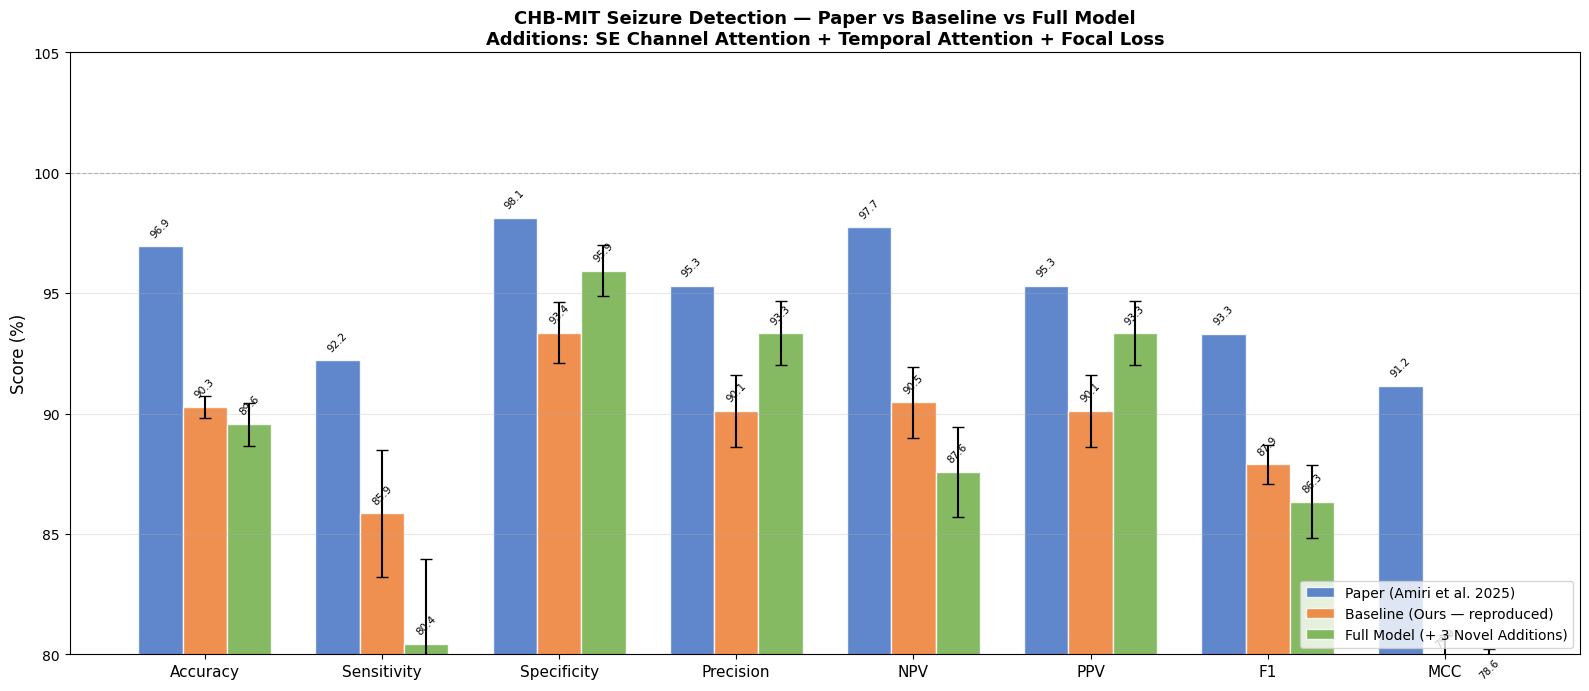

Chart saved: comparison_bar_chart.png


In [24]:
fig, ax = plt.subplots(figsize=(16, 7))

x     = np.arange(len(metrics_order))
width = 0.25

paper_vals   = [paper_values.get(m, 0) for m in metrics_order]
base_vals    = [df_baseline[m].mean() for m in metrics_order]
base_errs    = [df_baseline[m].std()  for m in metrics_order]
full_vals    = [df_full[m].mean()     for m in metrics_order]
full_errs    = [df_full[m].std()      for m in metrics_order]

b1 = ax.bar(x - width, paper_vals, width, label='Paper (Amiri et al. 2025)',
            color='#4472C4', alpha=0.85, edgecolor='white')
b2 = ax.bar(x,         base_vals,  width, label='Baseline (Ours — reproduced)',
            color='#ED7D31', alpha=0.85, edgecolor='white',
            yerr=base_errs, capsize=4, error_kw={'linewidth':1.5})
b3 = ax.bar(x + width, full_vals,  width, label='Full Model (+ 3 Novel Additions)',
            color='#70AD47', alpha=0.85, edgecolor='white',
            yerr=full_errs, capsize=4, error_kw={'linewidth':1.5})

# Value labels on top of bars
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                f'{h:.1f}', ha='center', va='bottom', fontsize=7.5, rotation=45)

ax.set_xticks(x)
ax.set_xticklabels(metrics_order, fontsize=11)
ax.set_ylim(80, 105)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('CHB-MIT Seizure Detection — Paper vs Baseline vs Full Model\n'
             'Additions: SE Channel Attention + Temporal Attention + Focal Loss',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.grid(alpha=0.3, axis='y')
ax.axhline(100, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.savefig('comparison_bar_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved: comparison_bar_chart.png")


## Cell 13 — Confusion Matrices: Baseline vs Full Model (on Test Set)

Retraining baseline on full train set ...

BASELINE — Test Set Results:
  Accuracy    : 90.95%
  Precision   : 91.28%
  Specificity : 94.24%
  Sensitivity : 86.25%
  NPV         : 90.74%
  PPV         : 91.28%
  F1          : 88.69%
  MCC         : 81.25%

Retraining full model on full train set ...

FULL MODEL — Test Set Results:
  Accuracy    : 89.64%
  Precision   : 95.05%
  Specificity : 97.13%
  Sensitivity : 78.94%
  NPV         : 86.84%
  PPV         : 95.05%
  F1          : 86.25%
  MCC         : 78.92%


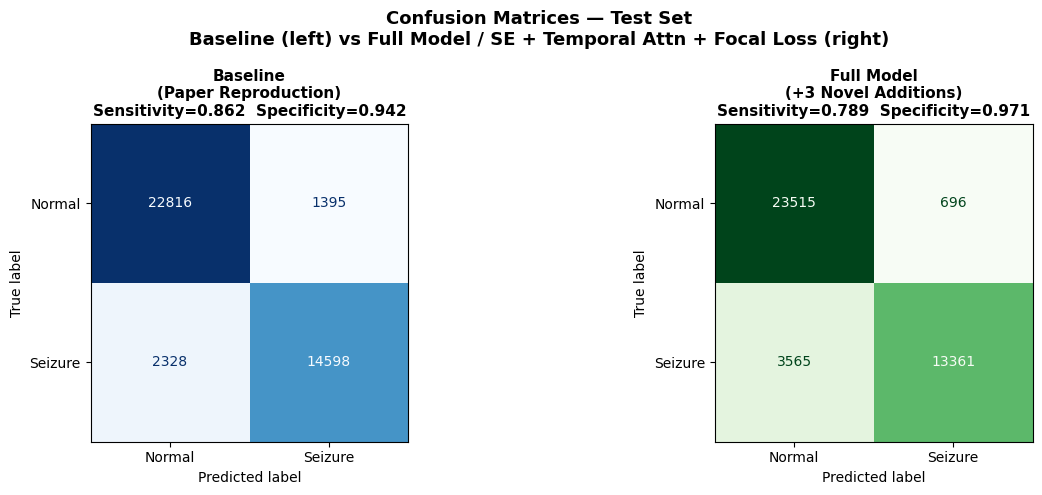


Saved: confusion_matrices.png

FINAL TEST SET SUMMARY
  Metric       |   Baseline | Full Model |    Delta
------------------------------------------------------------
  Accuracy     |      90.95 |      89.64 |    -1.31
  Sensitivity  |      86.25 |      78.94 |    -7.31
  Specificity  |      94.24 |      97.13 |    +2.89
  Precision    |      91.28 |      95.05 |    +3.77
  NPV          |      90.74 |      86.84 |    -3.91
  PPV          |      91.28 |      95.05 |    +3.77
  F1           |      88.69 |      86.25 |    -2.44
  MCC          |      81.25 |      78.92 |    -2.33


In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

# ── Retrain both models on full train set, evaluate on held-out test set ──────
def retrain_and_eval(flags, model_name):
    """Retrain on full X_train, evaluate on X_test."""
    classes = np.unique(y_train)
    weights = compute_class_weight('balanced', classes=classes, y=y_train)
    cw      = {int(k): v for k, v in zip(classes, weights)}

    model = build_model(INPUT_SHAPE, learning_rate=LEARNING_RATE, **flags)
    model.fit(
        X_train, y_train,
        validation_split=VAL_SPLIT,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        class_weight=cw,
        callbacks=[
            EarlyStopping(monitor='val_auc', patience=15,
                          restore_best_weights=True, mode='max', verbose=0),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                              patience=5, min_lr=1e-7, verbose=0)
        ],
        verbose=0
    )
    y_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_prob >= 0.5).astype(int)
    m      = compute_all_metrics(y_test, y_pred)
    cm     = confusion_matrix(y_test, y_pred)
    print(f"\n{model_name} — Test Set Results:")
    for k, v in m.items():
        print(f"  {k:12s}: {v:.2f}%")
    return cm, m

print("Retraining baseline on full train set ...")
cm_base, m_base = retrain_and_eval(
    {'use_channel_attention':False,'use_temporal_attention':False,'use_focal_loss':False},
    'BASELINE'
)

print("\nRetraining full model on full train set ...")
cm_full, m_full = retrain_and_eval(
    {'use_channel_attention':True,'use_temporal_attention':True,'use_focal_loss':True},
    'FULL MODEL'
)

# ── Side-by-side confusion matrices ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Confusion Matrices — Test Set\n'
             'Baseline (left) vs Full Model / SE + Temporal Attn + Focal Loss (right)',
             fontsize=13, fontweight='bold')

for ax, cm, title, color in [
    (axes[0], cm_base, 'Baseline\n(Paper Reproduction)', 'Blues'),
    (axes[1], cm_full, 'Full Model\n(+3 Novel Additions)', 'Greens'),
]:
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn + 1e-9)
    spec = tn / (tn + fp + 1e-9)
    ConfusionMatrixDisplay(cm, display_labels=['Normal','Seizure']).plot(
        ax=ax, cmap=color, colorbar=False)
    ax.set_title(f'{title}\nSensitivity={sens:.3f}  Specificity={spec:.3f}',
                 fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: confusion_matrices.png")

# ── Final summary ─────────────────────────────────────────────────────────────
print('\n' + '='*60)
print('FINAL TEST SET SUMMARY')
print('='*60)
print(f'  {"Metric":12s} | {"Baseline":>10} | {"Full Model":>10} | {"Delta":>8}')
print('-'*60)
for metric in metrics_order:
    b = m_base[metric]
    f = m_full[metric]
    print(f'  {metric:12s} | {b:>10.2f} | {f:>10.2f} | {f-b:>+8.2f}')
print('='*60)
